In [4]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import MinMaxScaler
# Load dataset
df = pd.read_csv("/kaggle/input/datasets/andrewmvd/heart-failure-clinical-data/heart_failure_clinical_records_dataset.csv")

In [5]:
print("First 5 Rows")
display(df.head())

First 5 Rows


,age,anaemia,creatinine_phosphokinase,diabetes,ejection_fraction,high_blood_pressure,platelets,serum_creatinine,serum_sodium,sex,smoking,time,DEATH_EVENT
0,75.0,0,582,0,20,1,265000.00,1.9,130,1,0,4,1
1,55.0,0,7861,0,38,0,263358.03,1.1,136,1,0,6,1
2,65.0,0,146,0,20,0,162000.00,1.3,129,1,1,7,1
3,50.0,1,111,0,20,0,210000.00,1.9,137,1,0,7,1
4,65.0,1,160,1,20,0,327000.00,2.7,116,0,0,8,1


In [6]:
print("Rows :", df.shape[0])
print("Columns :", df.shape[1])

print("\nData Types")
print(df.dtypes)

print("\nMissing Values")
print(df.isnull().sum())

print("\nDataset Info")
df.info()

Rows : 299
Columns : 13

Data Types
age                         float64
anaemia                       int64
creatinine_phosphokinase      int64
diabetes                      int64
ejection_fraction             int64
high_blood_pressure           int64
platelets                   float64
serum_creatinine            float64
serum_sodium                  int64
sex                           int64
smoking                       int64
time                          int64
DEATH_EVENT                   int64
dtype: object

Missing Values
age                         0
anaemia                     0
creatinine_phosphokinase    0
diabetes                    0
ejection_fraction           0
high_blood_pressure         0
platelets                   0
serum_creatinine            0
serum_sodium                0
sex                         0
smoking                     0
time                        0
DEATH_EVENT                 0
dtype: int64

Dataset Info
<class 'pandas.core.frame.DataFrame'>
RangeIndex:

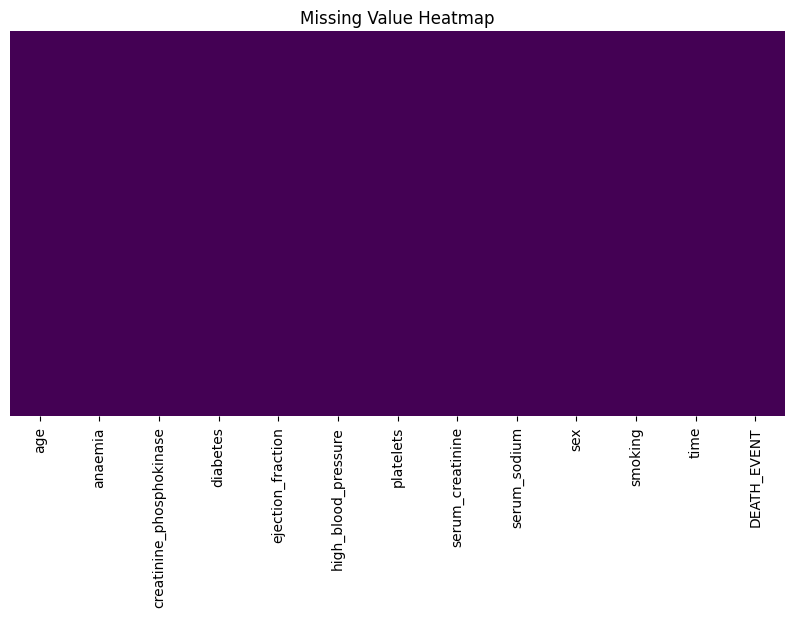

In [7]:
plt.figure(figsize=(10,5))
sns.heatmap(df.isnull(),
            cbar=False,
            cmap="viridis",
            yticklabels=False)

plt.title("Missing Value Heatmap")
plt.show()

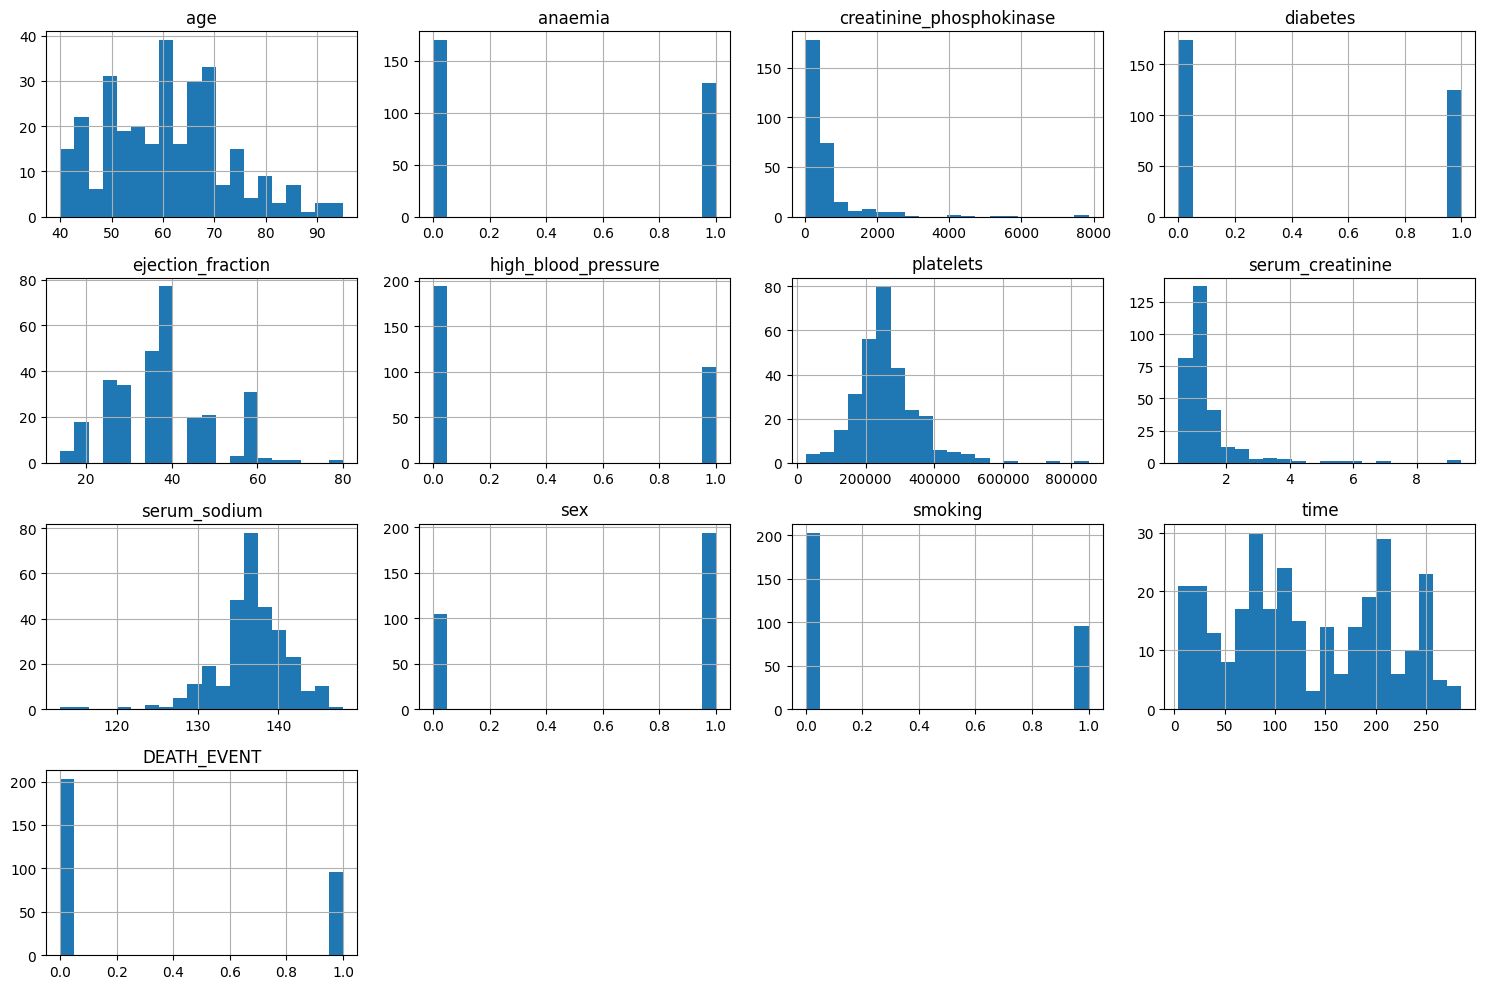

In [8]:
num_cols = df.columns

df[num_cols].hist(figsize=(15,10), bins=20)
plt.tight_layout()
plt.show()

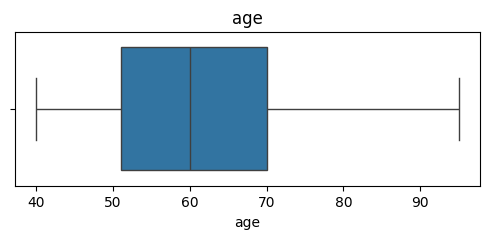

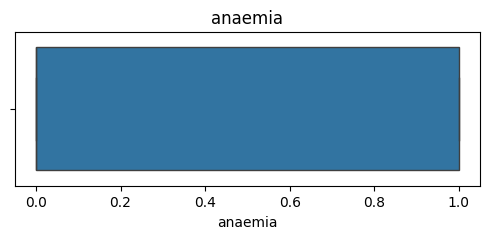

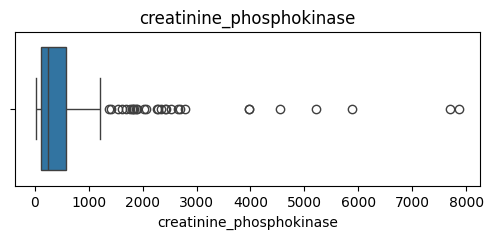

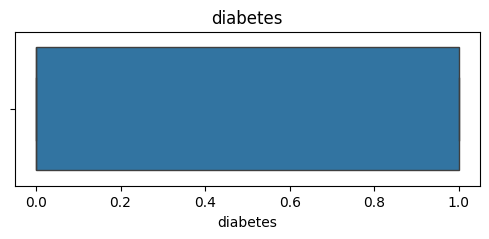

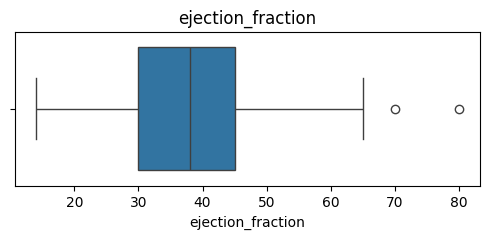

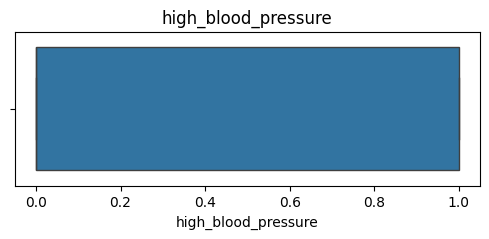

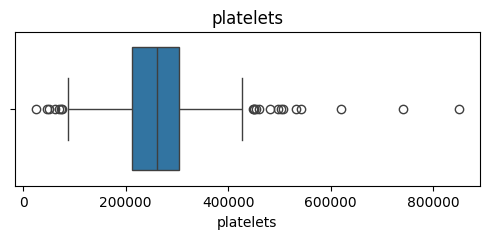

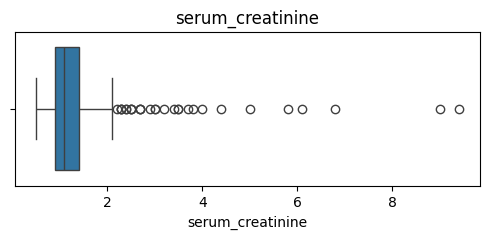

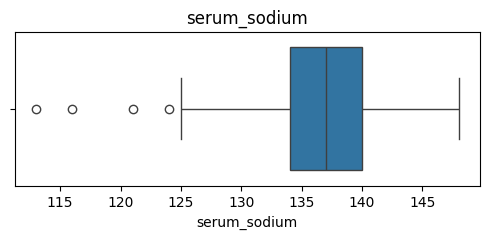

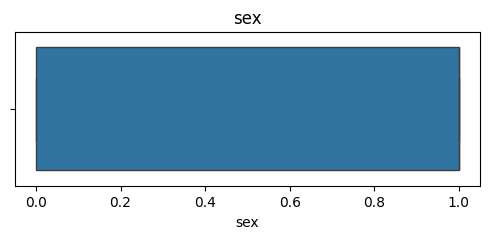

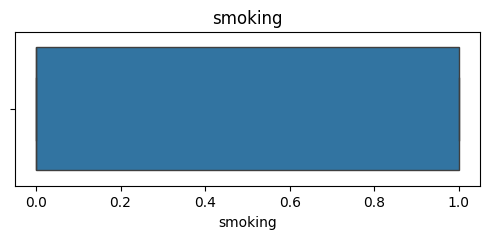

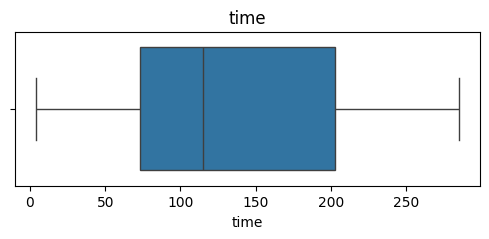

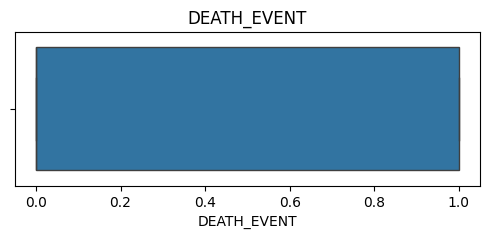

In [9]:
for col in num_cols:

    plt.figure(figsize=(6,2))

    sns.boxplot(x=df[col])

    plt.title(col)

    plt.show()

In [10]:
for col in df.columns:

    if df[col].isnull().sum()>0:

        df[col].fillna(df[col].median(), inplace=True)

In [11]:
print(df.isnull().sum())

age                         0
anaemia                     0
creatinine_phosphokinase    0
diabetes                    0
ejection_fraction           0
high_blood_pressure         0
platelets                   0
serum_creatinine            0
serum_sodium                0
sex                         0
smoking                     0
time                        0
DEATH_EVENT                 0
dtype: int64


In [12]:
def remove_outliers(df,column):

    Q1=df[column].quantile(0.25)

    Q3=df[column].quantile(0.75)

    IQR=Q3-Q1

    lower=Q1-1.5*IQR

    upper=Q3+1.5*IQR

    return df[(df[column]>=lower)&(df[column]<=upper)]


numeric_cols=[
'age',
'creatinine_phosphokinase',
'ejection_fraction',
'platelets',
'serum_creatinine',
'serum_sodium',
'time'
]

for col in numeric_cols:

    df=remove_outliers(df,col)

print(df.shape)

(224, 13)


In [13]:
df.loc[df['age']<0,'age']=df['age'].median()

df.loc[df['platelets']<0,'platelets']=df['platelets'].median()

df.loc[df['serum_creatinine']<0,'serum_creatinine']=df['serum_creatinine'].median()

df.loc[df['serum_sodium']<0,'serum_sodium']=df['serum_sodium'].median()

df.loc[df['ejection_fraction']<0,'ejection_fraction']=df['ejection_fraction'].median()

In [14]:
df['age_group']=pd.cut(df['age'],
                       bins=[0,40,60,120],
                       labels=['<40','40-60','>60'])

In [15]:
risk=df['ejection_fraction']*df['serum_creatinine']

df['risk_score']=(risk-risk.min())/(risk.max()-risk.min())

In [16]:
df=pd.get_dummies(df,
                  columns=['age_group'],
                  drop_first=True)

print(df.head())

    age  anaemia  creatinine_phosphokinase  diabetes  ejection_fraction  \
0  75.0        0                       582         0                 20   
2  65.0        0                       146         0                 20   
3  50.0        1                       111         0                 20   
5  90.0        1                        47         0                 40   
6  75.0        1                       246         0                 15   

   high_blood_pressure  platelets  serum_creatinine  serum_sodium  sex  \
0                    1   265000.0               1.9           130    1   
2                    0   162000.0               1.3           129    1   
3                    0   210000.0               1.9           137    1   
5                    1   204000.0               2.1           132    1   
6                    0   127000.0               1.2           137    1   

   smoking  time  DEATH_EVENT  risk_score  age_group_40-60  age_group_>60  
0        0     4            

In [17]:
scaler=MinMaxScaler()

scale_cols=[
'age',
'creatinine_phosphokinase',
'ejection_fraction',
'platelets',
'serum_creatinine',
'serum_sodium',
'time',
'risk_score'
]

df[scale_cols]=scaler.fit_transform(df[scale_cols])

In [19]:
original=pd.read_csv("/kaggle/input/datasets/andrewmvd/heart-failure-clinical-data/heart_failure_clinical_records_dataset.csv")

print("Before Cleaning")

print(original.describe())

Before Cleaning
              age     anaemia  creatinine_phosphokinase    diabetes  \
count  299.000000  299.000000                299.000000  299.000000   
mean    60.833893    0.431438                581.839465    0.418060   
std     11.894809    0.496107                970.287881    0.494067   
min     40.000000    0.000000                 23.000000    0.000000   
25%     51.000000    0.000000                116.500000    0.000000   
50%     60.000000    0.000000                250.000000    0.000000   
75%     70.000000    1.000000                582.000000    1.000000   
max     95.000000    1.000000               7861.000000    1.000000   

       ejection_fraction  high_blood_pressure      platelets  \
count         299.000000           299.000000     299.000000   
mean           38.083612             0.351171  263358.029264   
std            11.834841             0.478136   97804.236869   
min            14.000000             0.000000   25100.000000   
25%            30.000000

In [20]:
print("After Cleaning")

print(df.describe())

After Cleaning
              age    anaemia  creatinine_phosphokinase    diabetes  \
count  224.000000  224.00000                224.000000  224.000000   
mean     0.378355    0.46875                  0.261896    0.419643   
std      0.217202    0.50014                  0.238499    0.494606   
min      0.000000    0.00000                  0.000000    0.000000   
25%      0.181818    0.00000                  0.072099    0.000000   
50%      0.363636    0.00000                  0.155290    0.000000   
75%      0.545455    1.00000                  0.470990    1.000000   
max      1.000000    1.00000                  1.000000    1.000000   

       ejection_fraction  high_blood_pressure   platelets  serum_creatinine  \
count         224.000000           224.000000  224.000000        224.000000   
mean            0.474090             0.379464    0.438902          0.352381   
std             0.229624             0.486340    0.220176          0.218530   
min             0.000000             0

In [21]:
summary=pd.DataFrame({

'Mean':df.mean(numeric_only=True),

'Median':df.median(numeric_only=True),

'Std Dev':df.std(numeric_only=True)

})

summary

,Mean,Median,Std Dev
age,0.378355,0.363636,0.217202
anaemia,0.468750,0.000000,0.500140
creatinine_phosphokinase,0.261896,0.155290,0.238499
diabetes,0.419643,0.000000,0.494606
ejection_fraction,0.474090,0.470588,0.229624
high_blood_pressure,0.379464,0.000000,0.486340
platelets,0.438902,0.460656,0.220176
serum_creatinine,0.352381,0.333333,0.218530
serum_sodium,0.523680,0.521739,0.165510
sex,0.642857,1.000000,0.480231


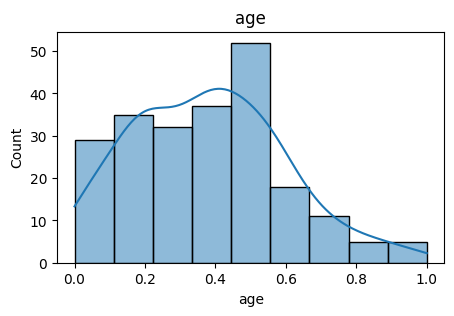

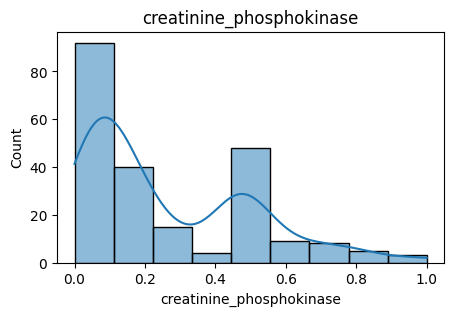

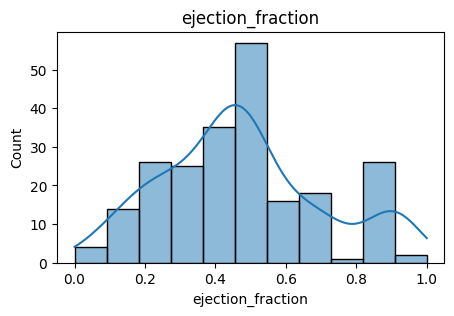

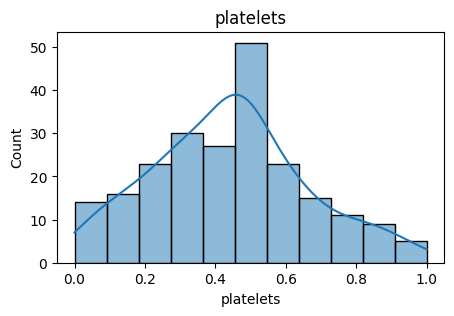

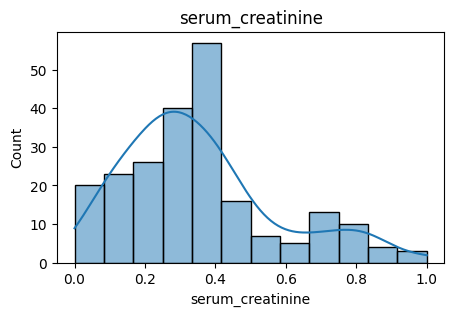

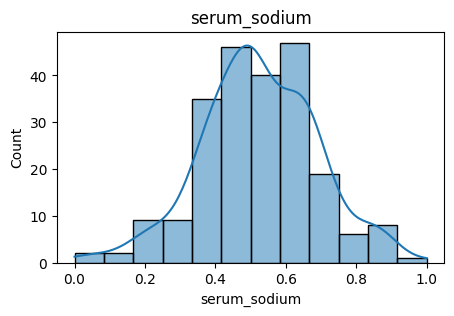

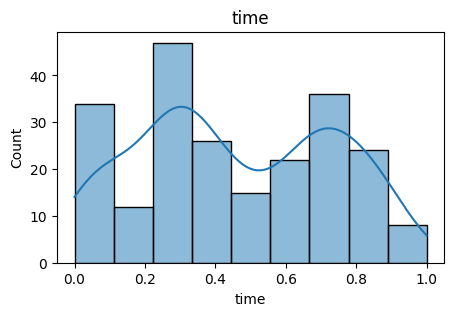

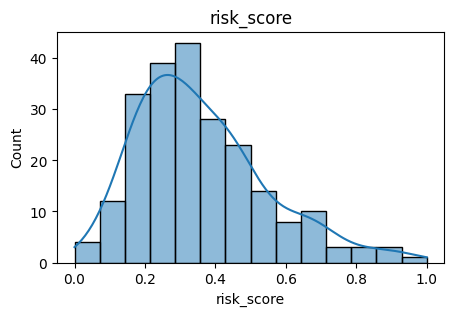

In [22]:
for col in scale_cols:

    plt.figure(figsize=(5,3))

    sns.histplot(df[col],kde=True)

    plt.title(col)

    plt.show()

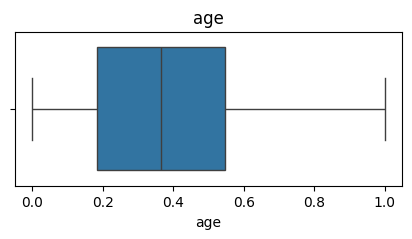

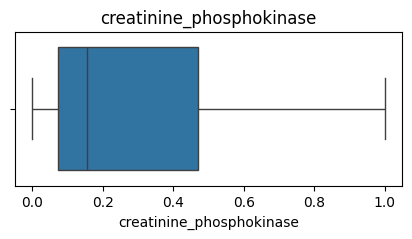

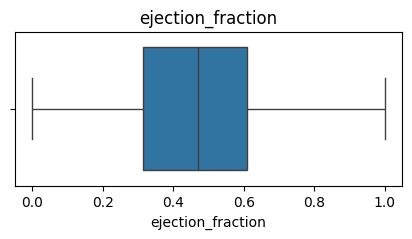

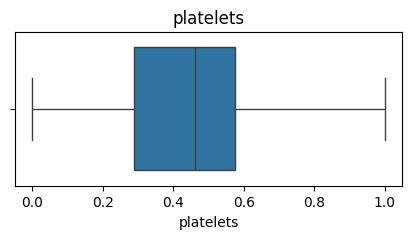

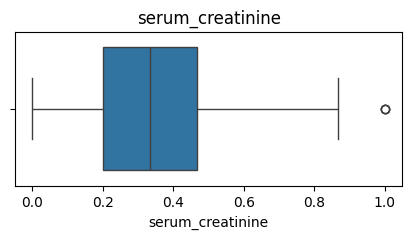

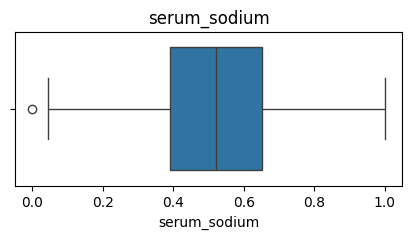

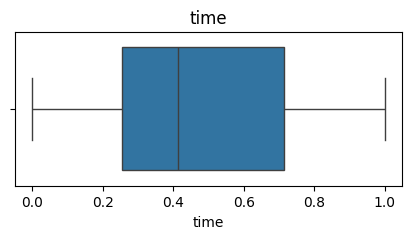

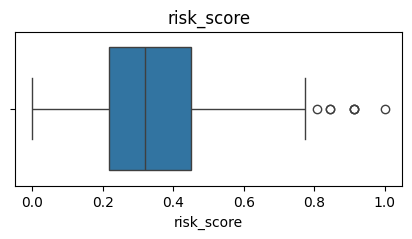

In [23]:
for col in scale_cols:

    plt.figure(figsize=(5,2))

    sns.boxplot(x=df[col])

    plt.title(col)

    plt.show()

In [24]:
print(df.isnull().sum())

print("Total Missing Values =",df.isnull().sum().sum())

age                         0
anaemia                     0
creatinine_phosphokinase    0
diabetes                    0
ejection_fraction           0
high_blood_pressure         0
platelets                   0
serum_creatinine            0
serum_sodium                0
sex                         0
smoking                     0
time                        0
DEATH_EVENT                 0
risk_score                  0
age_group_40-60             0
age_group_>60               0
dtype: int64
Total Missing Values = 0


In [25]:
df.to_csv("heart_failure_cleaned.csv",index=False)

print("Cleaned dataset saved successfully.")

Cleaned dataset saved successfully.
